## KNN: ImageNet (find best k)

Load default ResNet50 trained on ImageNet and predict concepts for several classes.

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import glob, os, cv2, pickle
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import log_loss
from sklearn.metrics.pairwise import cosine_similarity
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import GlobalAveragePooling2D

In [23]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2024-03-05 18:40:56.683890: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 47125 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [24]:
IMAGES_PATH = '../data/Unsplash/images_optimize_k/'
CONCEPTS_PATH = '../data/Unsplash/concepts_broden/' # {concepts_broden, concepts_stab, prototypes}
img_height = img_width = 224

In [25]:
concepts = [c.split('/')[-1] for c in glob.glob(CONCEPTS_PATH + '*')]
concepts

['dotted', 'chequered', 'striped']

### Load Training Images

In [26]:
classes = [c.split('/')[-1] for c in sorted(glob.glob(IMAGES_PATH + '*'))]
classes

['cheetah', 'snake', 'tiger', 'turtle', 'zebra']

In [27]:
train_set = tf.keras.utils.image_dataset_from_directory(
    IMAGES_PATH,
    shuffle=False,
    seed=123,
    image_size=(img_height, img_width),
    batch_size=None)

Found 432 files belonging to 5 classes.


In [28]:
# Preprocess raw images (required by resnet initialized with imagenet weights)
train_set = train_set.map(lambda x, y: (tf.keras.applications.resnet50.preprocess_input(x), y))

In [29]:
# Get concept label vector from tf.Dataset
y_true_img = np.asarray([lab.numpy() for _, lab in train_set])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


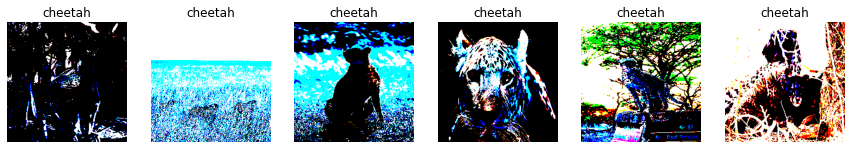

In [30]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = 6
with tf.device('/CPU:0'):
    i=0
    for img, lab in train_set.take(num_cols):
        plt.subplot(1, num_cols, i + 1)
        plt.imshow(img)
        plt.title(classes[lab.numpy()])
        plt.axis("off")
        i+=1
plt.show()

### Load Concept Images

In [31]:
concept_set = tf.keras.utils.image_dataset_from_directory(
    CONCEPTS_PATH,
    shuffle=False,
    seed=123,
    image_size=(img_height, img_width),
    batch_size=None)

Found 90 files belonging to 3 classes.


In [32]:
# Preprocess raw images (required by resnet initialized with imagenet weights)
concept_set = concept_set.map(lambda x, y: (tf.keras.applications.resnet50.preprocess_input(x), y))

In [33]:
# Get concept label vector from tf.Dataset
y_true_con = np.asarray([lab.numpy() for _, lab in concept_set])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


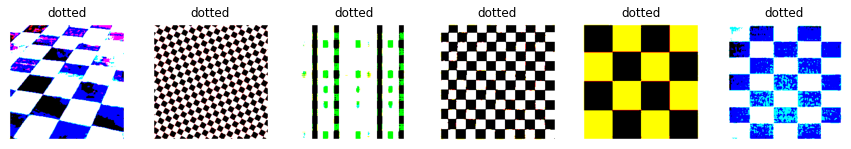

In [34]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = 6
with tf.device('/CPU:0'):
    i=0
    for img, lab in concept_set.take(num_cols):
        plt.subplot(1, num_cols, i + 1)
        plt.imshow(img)
        plt.title(concepts[lab.numpy()])
        plt.axis("off")
        i+=1
plt.show()

### Load Random Images

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i

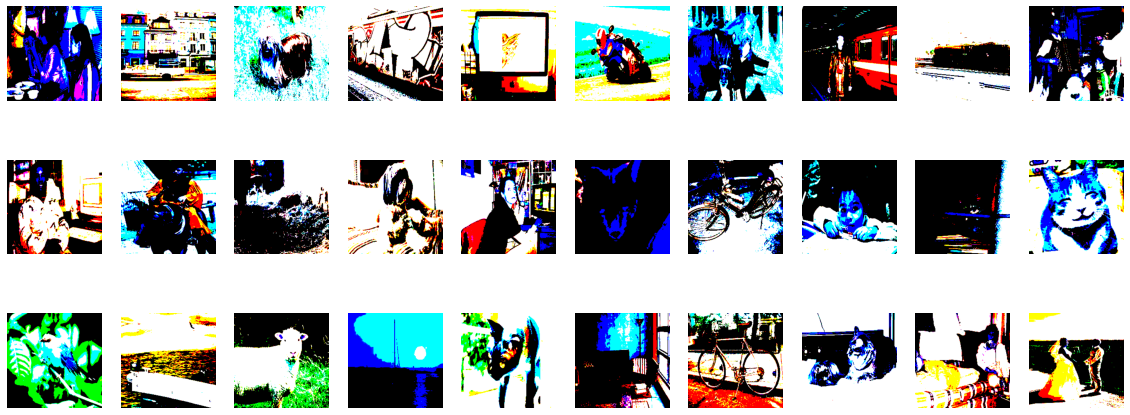

In [35]:
random_img_folder = '../data/broden1_224/images/pascal/'
input_size = img_height

random_imgs = os.listdir(random_img_folder)
random_imgs_filter = lambda f : all([rm not in f for rm in ['object', 'color', 'part']]) # only take 'natural' image

# Load same random images used for tcav fungi
with open('./beexplainable/metafiles/Fungi/raw/fungi_tcav_random.pickle', 'rb') as handle:
    files = pickle.load(handle)

random_dataset = [cv2.imread(random_img_folder+img)[...,::-1] for img in files]
random_dataset = [tf.image.resize(img, [img_width, img_height]) for img in random_dataset]
random_dataset = np.array([tf.keras.applications.resnet50.preprocess_input(img) for img in random_dataset])

plt.figure(figsize = (20, 8))
for i in range(30):
    plt.subplot(3, 10, i+1)
    plt.imshow(random_dataset[i])
    plt.axis('off')

### Predict Concepts/Prototypes

In [36]:
# Load ResNet backbone
base_model = ResNet50(input_shape=(img_height, img_width, 3), weights='imagenet', include_top=False)

In [37]:
# Concatenate concept sets with random set
con_rand_set = []
for img, _ in concept_set.as_numpy_iterator():
    con_rand_set.append(img)
con_rand_set = np.asarray(con_rand_set)
con_rand_set = np.concatenate((con_rand_set, random_dataset))
print(con_rand_set.shape)

y_true_con_rand = np.concatenate((y_true_con, np.array([len(concepts)]*len(random_dataset))))
print(y_true_con_rand.shape)

(1090, 224, 224, 3)
(1090,)


In [38]:
# Extract features from concepts and random set
res_con_rand = GlobalAveragePooling2D()(base_model.predict(con_rand_set))
tf.shape(res_con_rand)

<tf.Tensor: shape=(2,), dtype=int32, numpy=array([1090, 2048], dtype=int32)>

In [39]:
# Extract features for all samples
train_activations = GlobalAveragePooling2D()(base_model.predict(train_set.batch(32)))
train_activations.shape

TensorShape([432, 2048])

#### SD Protos, multiple random partitions, one kNN for all concepts

In [19]:
# One-hot-encode the concepts/prototypes
concept_basis = OneHotEncoder().fit_transform([[0], [1], [2], [3], [4]]).toarray()
lookup_cls_concepts = [concept_basis[0], # cheetah_proto
                       concept_basis[1], # snake_proto
                       concept_basis[2], # tiger_proto
                       concept_basis[3], # turtle_proto
                       concept_basis[4]] # zebra_proto
lookup_cls_concepts[0]

array([1., 0., 0., 0., 0.])

In [20]:
k_vals = np.arange(2,30,2)
num_parts = 50 # how often to randomly select subsets of the random set
cos_sims, bces = [], []
for k in k_vals:
    knn_probs = np.zeros((len(train_activations), len(concepts)+1)) # matrix of aggregated probs for every sample and every concept
    for i in range(num_parts):
        # Select random indexes (starting after last concept img index)
        random_ids = np.random.choice( np.arange(len(y_true_con), len(con_rand_set)), 30,
                                       replace = False)

        # Overall index vector (concept indexes, then current random subset indexes)
        con_rand_ids = np.concatenate( (np.arange(len(y_true_con)), random_ids) )

        # Fit a kNN on current partition
        neigh = KNeighborsClassifier(n_neighbors=k)
        neigh.fit(res_con_rand.numpy()[con_rand_ids], y_true_con_rand[con_rand_ids])

        # Predict concepts for all test vectors
        knn_probs += neigh.predict_proba(train_activations)

    # Average over number of random partitions
    knn_probs /= num_parts

    bce, cos_sim = 0.0, 0.0
    for i in range(len(y_true_img)):

        # Get true concept(s) based on true class
        true_con = lookup_cls_concepts[y_true_img[i]]

        # Compute binary cross entropy
        bce += log_loss(true_con, knn_probs[i, :-1]) # leave random comp.out
        # Compute cosine sim.
        cos_sim += cosine_similarity(true_con.reshape(1, -1), knn_probs[i, :-1].reshape(1, -1))[0][0]

    cos_sims.append( cos_sim/len(y_true_img) )
    bces.append( bce/len(y_true_img) )
    if k%10 == 0: print(k)

10
20


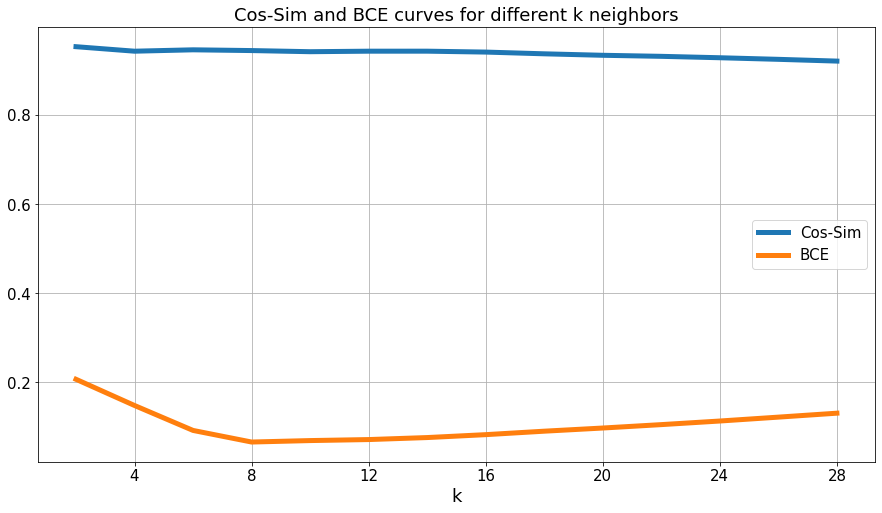

In [21]:
fsize=15
fig = plt.figure(figsize=(15,8))
plt.plot(k_vals, cos_sims, linewidth=5)
plt.plot(k_vals, bces, linewidth=5)
plt.title('Cos-Sim and BCE curves for different k neighbors', fontsize=fsize+3)
plt.xticks(k_vals[1::2], fontsize=fsize);plt.xlabel('k', fontsize=fsize+3)
plt.yticks(fontsize=fsize)
plt.legend(['Cos-Sim', 'BCE'], loc='center right' , fontsize=fsize)
plt.grid()
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/optimize_k_imagenet_sd_protos_rand30.png', bbox_inches='tight')
plt.show()

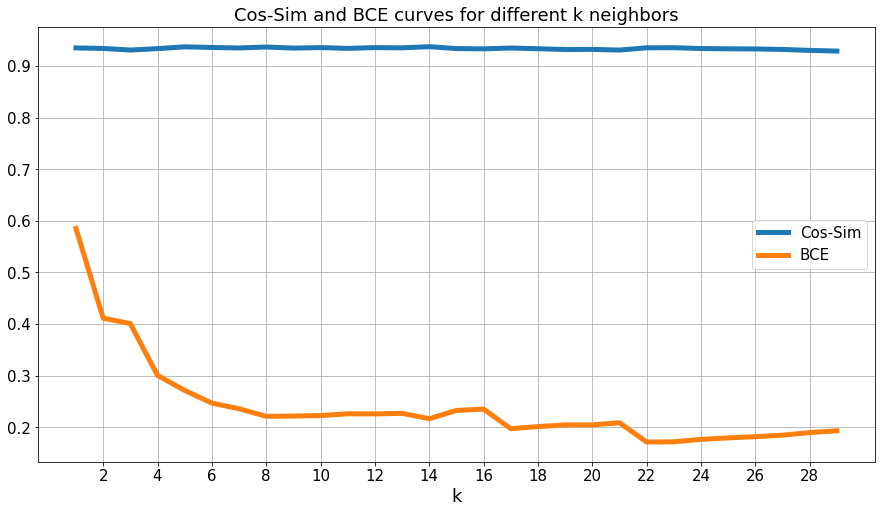

In [23]:
fsize=15
fig = plt.figure(figsize=(15,8))
plt.plot(k_vals, cos_sims, linewidth=5)
plt.plot(k_vals, bces, linewidth=5)
plt.title('Cos-Sim and BCE curves for different k neighbors', fontsize=fsize+3)
plt.xticks(k_vals[1::2], fontsize=fsize);plt.xlabel('k', fontsize=fsize+3)
plt.yticks(fontsize=fsize)
plt.legend(['Cos-Sim', 'BCE'], loc='center right' , fontsize=fsize)
plt.grid()
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/optimize_k_imagenet_sd_protos.png', bbox_inches='tight')
plt.show()

#### Broden, multiple random partitions, one knn for all concepts

In [40]:
# One-hot-encode the concepts/prototypes
concept_basis = OneHotEncoder().fit_transform([[0], [1], [2]]).toarray()
lookup_cls_concepts = [concept_basis[1], # cheetah -> dotted
                       concept_basis[0], # snake -> chequered
                       concept_basis[2], # tiger -> striped
                       concept_basis[0], # turtle -> chequered
                       concept_basis[2]] # zebra -> striped

In [43]:
k_vals = np.arange(10,40,2)
num_parts = 50 # how often to randomly select subsets of the random set
cos_sims, bces = [], []
for k in k_vals:
    knn_probs = np.zeros((len(train_activations), len(concepts)+1)) # matrix of aggregated probs for every sample and every concept
    for i in range(num_parts):
        # Select random indexes (starting after last concept img index)
        random_ids = np.random.choice( np.arange(len(y_true_con), len(con_rand_set)), 30,
                                       replace = False)

        # Overall index vector (concept indexes, then current random subset indexes)
        con_rand_ids = np.concatenate( (np.arange(len(y_true_con)), random_ids) )

        # Fit a kNN on current partition
        neigh = KNeighborsClassifier(n_neighbors=k)
        neigh.fit(res_con_rand.numpy()[con_rand_ids], y_true_con_rand[con_rand_ids])

        # Predict concepts for all test vectors
        knn_probs += neigh.predict_proba(train_activations)

    # Average over number of random partitions
    knn_probs /= num_parts

    bce, cos_sim = 0.0, 0.0
    for i in range(len(y_true_img)):

        # Get true concept(s) based on true class
        true_con = lookup_cls_concepts[y_true_img[i]]

        # Compute binary cross entropy
        bce += log_loss(true_con, knn_probs[i, :-1]) # leave random comp.out
        # Compute cosine sim.
        cos_sim += cosine_similarity(true_con.reshape(1, -1), knn_probs[i, :-1].reshape(1, -1))[0][0]

    cos_sims.append( cos_sim/len(y_true_img) )
    bces.append( bce/len(y_true_img) )
    if k%10 == 0: print(k)

10
20
30


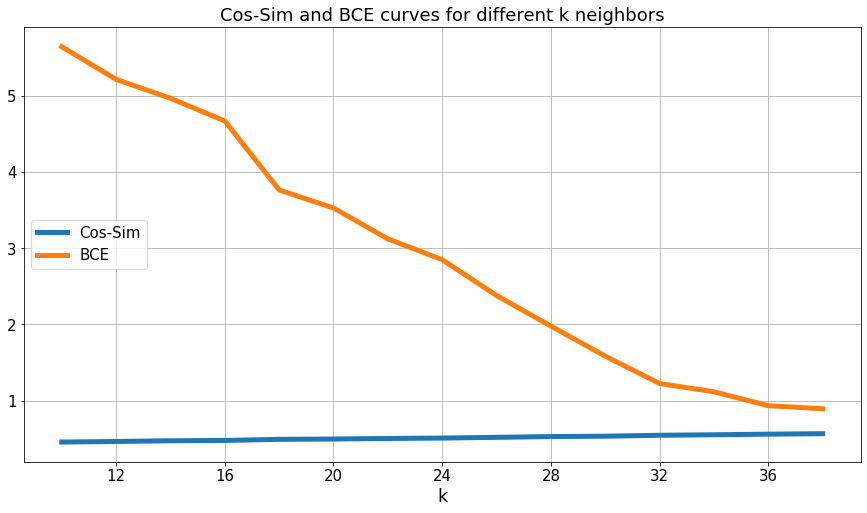

In [44]:
fsize=15
fig = plt.figure(figsize=(15,8))
plt.plot(k_vals, cos_sims, linewidth=5)
plt.plot(k_vals, bces, linewidth=5)
plt.title('Cos-Sim and BCE curves for different k neighbors', fontsize=fsize+3)
plt.xticks(k_vals[1::2], fontsize=fsize);plt.xlabel('k', fontsize=fsize+3)
plt.yticks(fontsize=fsize)
plt.legend(['Cos-Sim', 'BCE'], loc='center left' , fontsize=fsize)
plt.grid()
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/optimize_k_imagenet_broden_rand30.png', bbox_inches='tight')
plt.show()

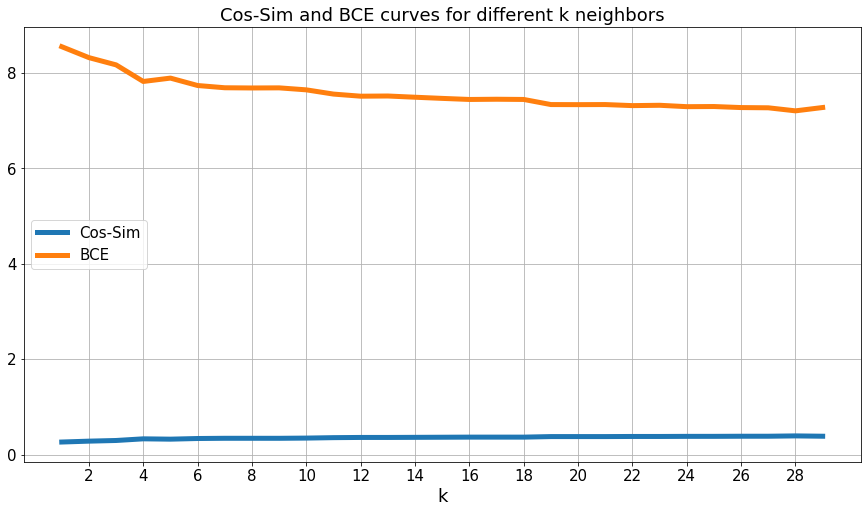

In [45]:
fsize=15
fig = plt.figure(figsize=(15,8))
plt.plot(k_vals, cos_sims, linewidth=5)
plt.plot(k_vals, bces, linewidth=5)
plt.title('Cos-Sim and BCE curves for different k neighbors', fontsize=fsize+3)
plt.xticks(k_vals[1::2], fontsize=fsize);plt.xlabel('k', fontsize=fsize+3)
plt.yticks(fontsize=fsize)
plt.legend(['Cos-Sim', 'BCE'], loc='center left' , fontsize=fsize)
plt.grid()
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/optimize_k_imagenet_broden.png', bbox_inches='tight')
plt.show()